# Jumeau numérique — CatBoost


## 1. Import des bibliothèques

In [1]:
import argparse
import json
from pathlib import Path

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier, Pool, cv
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, log_loss)
from sklearn.model_selection import train_test_split

## 2. Collecte et affichage des données

In [2]:
dataset = pd.read_csv("digitalTwin.csv")
dataset.shape
dataset.columns

Index(['Equipment', 'HealthIndex', 'EngineTemp', 'Vibration', 'Pressure',
       'State'],
      dtype='object')

In [3]:
print(dataset.head(10).to_string(index=False))
dataset.info()
print(dataset["State"].value_counts().rename_axis("State").to_frame("Nombre"))

Equipment  HealthIndex  EngineTemp  Vibration  Pressure    State
   EQ-240        90.74       67.81       3.91    292.70  Warning
    EQ-14        84.60       53.83       2.46    284.46  Warning
   EQ-270        88.32       66.18       8.93    128.07 Critical
   EQ-106        27.12       99.42       4.99    102.04  Healthy
   EQ-175        92.48      112.92       4.23    282.61 Critical
   EQ-213        11.18       51.40       7.58    174.57 Critical
    EQ-20        57.33      103.52       5.78    225.12  Warning
   EQ-150        26.98      116.54       5.29    251.24 Critical
    EQ-93        91.34      117.97       8.21    102.23  Warning
   EQ-275        76.94       68.04       9.24    114.93  Warning
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Equipment    10000 non-null  object 
 1   HealthIndex  10000 non-null  float64
 2   Engin

## 3. Nettoyage des données

In [4]:
print("Doublons :", dataset.duplicated().sum())
print(dataset.isnull().sum())

dataset = dataset.drop_duplicates()
dataset = dataset.dropna()
colonnes_numeriques = ["HealthIndex", "EngineTemp", "Vibration", "Pressure"]
dataset[colonnes_numeriques] = dataset[colonnes_numeriques].apply(pd.to_numeric, errors="coerce")
dataset = dataset.dropna(subset=colonnes_numeriques)
dataset = dataset[(dataset[colonnes_numeriques] >= 0).all(axis=1)]
print("Dimensions après nettoyage :", dataset.shape)
print(dataset.isnull().sum())

Doublons : 0
Equipment      0
HealthIndex    0
EngineTemp     0
Vibration      0
Pressure       0
State          0
dtype: int64
Dimensions après nettoyage : (10000, 6)
Equipment      0
HealthIndex    0
EngineTemp     0
Vibration      0
Pressure       0
State          0
dtype: int64


## 4. Analyse exploratoire (EDA)

count    10000.00
mean        50.16
std         28.87
min          0.00
25%         25.37
50%         50.06
75%         75.33
max         99.99
Name: HealthIndex, dtype: float64
          HealthIndex  EngineTemp  Vibration  Pressure
State                                                 
Critical        50.25       84.79       5.09    225.94
Healthy         50.38       85.45       5.00    224.57
Warning         49.84       85.02       5.05    224.74


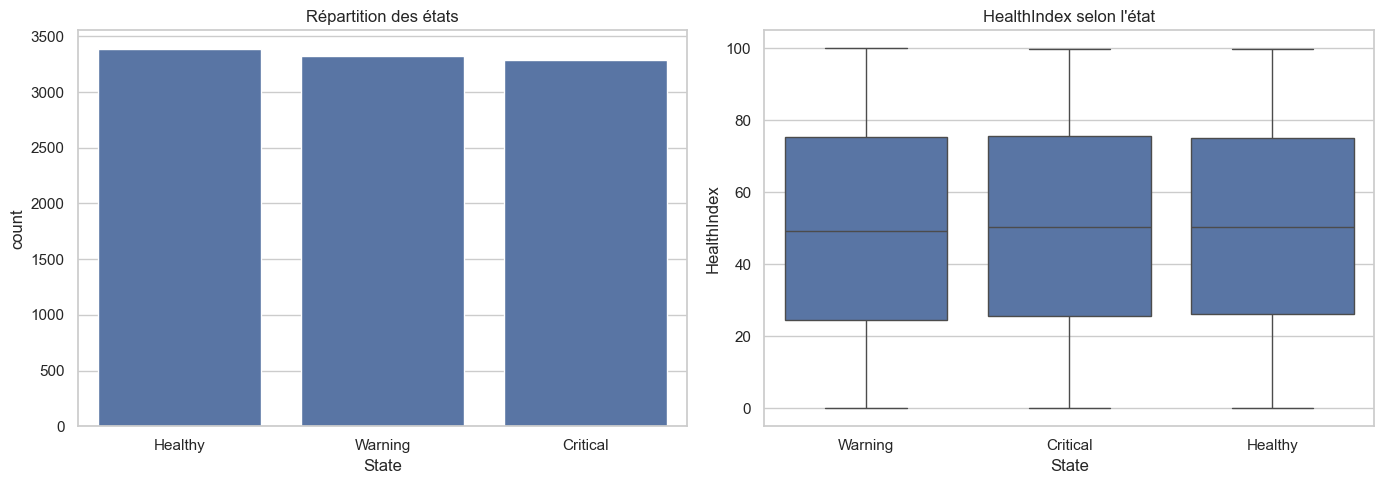

In [5]:
print(dataset["HealthIndex"].describe().round(2))
print(dataset.groupby("State")[colonnes_numeriques].mean().round(2))

sns.set_theme(style="whitegrid")
figure, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=dataset, x="State", order=dataset["State"].value_counts().index, ax=axes[0])
axes[0].set_title("Répartition des états")
sns.boxplot(data=dataset, x="State", y="HealthIndex", ax=axes[1])
axes[1].set_title("HealthIndex selon l'état")
figure.tight_layout()
plt.show()

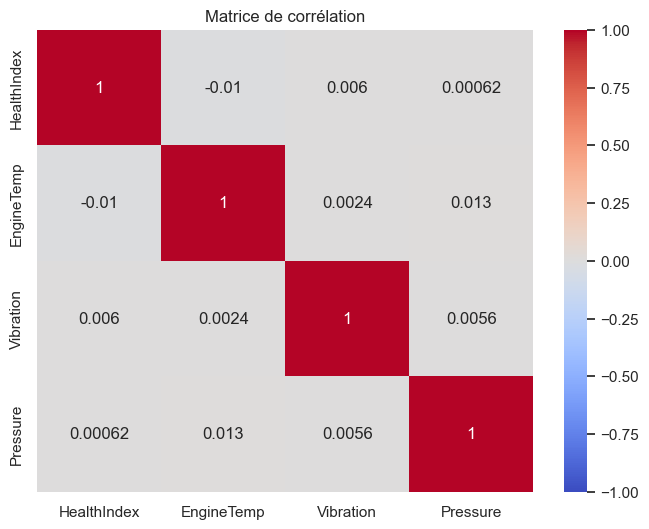

In [6]:
correlations = dataset[colonnes_numeriques].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(correlations, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation")
plt.show()

## 5. Ingénierie des caractéristiques

In [7]:
dataset["TempVibration"] = dataset["EngineTemp"] * dataset["Vibration"]
dataset["PressureVibrationRatio"] = dataset["Pressure"] / (dataset["Vibration"] + 0.01)
dataset["HealthRisk"] = 100 - dataset["HealthIndex"]

features = ["HealthIndex", "EngineTemp", "Vibration", "Pressure", "TempVibration", "PressureVibrationRatio", "HealthRisk"]
X = dataset[features]
y = dataset["State"]
print(X.head())
print(y.value_counts())

   HealthIndex  EngineTemp  Vibration  Pressure  TempVibration  \
0        90.74       67.81       3.91    292.70       265.1371   
1        84.60       53.83       2.46    284.46       132.4218   
2        88.32       66.18       8.93    128.07       590.9874   
3        27.12       99.42       4.99    102.04       496.1058   
4        92.48      112.92       4.23    282.61       477.6516   

   PressureVibrationRatio  HealthRisk  
0               74.668367        9.26  
1              115.165992       15.40  
2               14.325503       11.68  
3               20.408000       72.88  
4               66.653302        7.52  
State
Healthy     3384
Warning     3325
Critical    3291
Name: count, dtype: int64


## 6. Entraînement du modèle CatBoost

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

modele_catboost = CatBoostClassifier(iterations=300, depth=6, learning_rate=0.05, loss_function="MultiClass", eval_metric="TotalF1", random_seed=42, verbose=50)
modele_catboost.fit(X_train, y_train, eval_set=(X_test, y_test), early_stopping_rounds=30)
modele_catboost.save_model("catboost_state_model.cbm")

0:	learn: 0.3605603	test: 0.3327499	best: 0.3327499 (0)	total: 223ms	remaining: 1m 6s
Stopped by overfitting detector  (30 iterations wait)

bestTest = 0.340610692
bestIteration = 5

Shrink model to first 6 iterations.


## 7. Évaluation du modèle

Accuracy CatBoost : 0.3445
F1 pondéré CatBoost : 0.3406
Log loss CatBoost : 1.0987
              precision    recall  f1-score   support

    Critical       0.35      0.31      0.33       658
     Healthy       0.34      0.45      0.39       677
     Warning       0.34      0.27      0.30       665

    accuracy                           0.34      2000
   macro avg       0.34      0.34      0.34      2000
weighted avg       0.34      0.34      0.34      2000



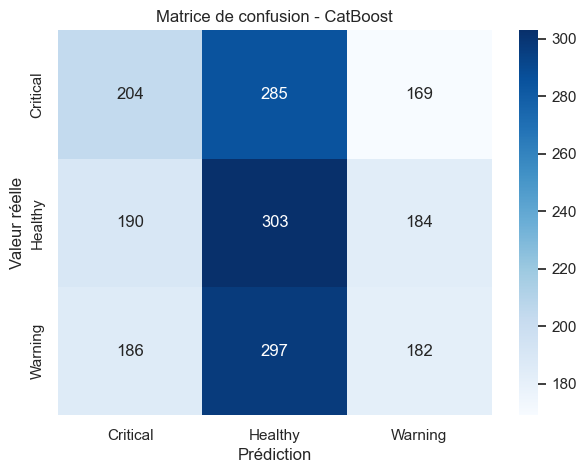

Accuracy baseline : 0.3385


In [9]:
predictions = modele_catboost.predict(X_test).ravel()
probabilites = modele_catboost.predict_proba(X_test)
print("Accuracy CatBoost :", round(accuracy_score(y_test, predictions), 4))
print("F1 pondéré CatBoost :", round(f1_score(y_test, predictions, average="weighted"), 4))
print("Log loss CatBoost :", round(log_loss(y_test, probabilites, labels=modele_catboost.classes_), 4))
print(classification_report(y_test, predictions))

matrice = confusion_matrix(y_test, predictions, labels=modele_catboost.classes_)
plt.figure(figsize=(7, 5))
sns.heatmap(matrice, annot=True, fmt="d", cmap="Blues", xticklabels=modele_catboost.classes_, yticklabels=modele_catboost.classes_)
plt.xlabel("Prédiction"); plt.ylabel("Valeur réelle"); plt.title("Matrice de confusion - CatBoost")
plt.show()

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Accuracy baseline :", round(accuracy_score(y_test, baseline.predict(X_test)), 4))

## 8. Explicabilité : CatBoost, SHAP et LIME

EngineTemp                24.999000
Pressure                  21.256283
Vibration                 15.432659
HealthRisk                12.630979
TempVibration              9.185528
HealthIndex                8.692632
PressureVibrationRatio     7.802919
dtype: float64


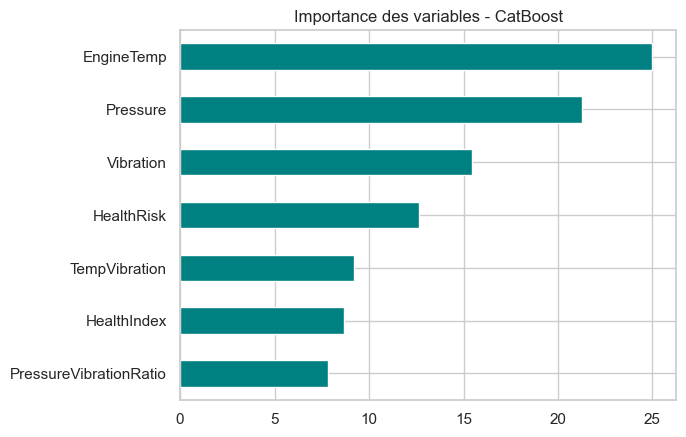

In [10]:
importances = pd.Series(modele_catboost.get_feature_importance(), index=features).sort_values()
print(importances.sort_values(ascending=False))
importances.plot(kind="barh", color="teal", title="Importance des variables - CatBoost")
plt.show()



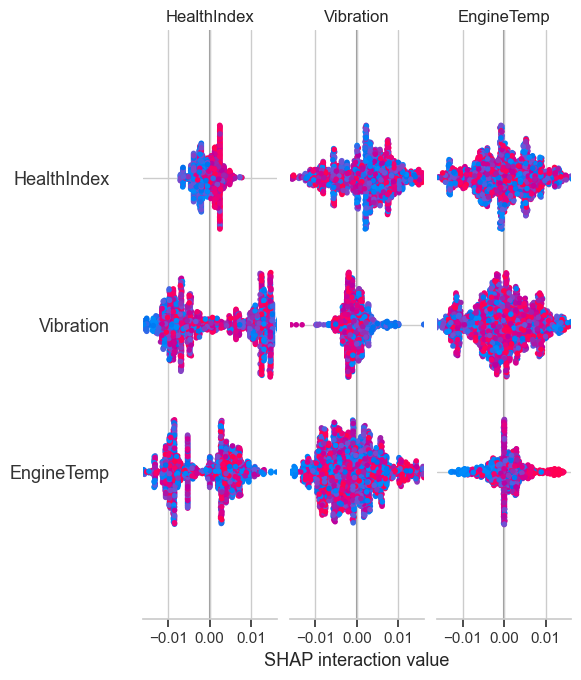

In [ ]:
try:
    import shap
    explainer = shap.TreeExplainer(modele_catboost)
    shap_values = explainer.shap_values(X_test)
    shap.summary_plot(shap_values, X_test, feature_names=features)
except ImportError:
    print("SHAP n'est pas installé.")

try:
    from lime.lime_tabular import LimeTabularExplainer
    lime_explainer = LimeTabularExplainer(X_train.values, feature_names=features, class_names=list(modele_catboost.classes_), mode="classification")
    lime_explanation = lime_explainer.explain_instance(X_test.iloc[0].values, modele_catboost.predict_proba)
    lime_explanation.show_in_notebook()
except ImportError:
    print("LIME n'est pas installé.")